# Gray - Binary encoding conversion

## For a particular theta

{'1100': 275, '1111': 71, '0011': 458, '1010': 753, '1001': 2157, '0110': 1737, '0000': 3948, '0101': 601}


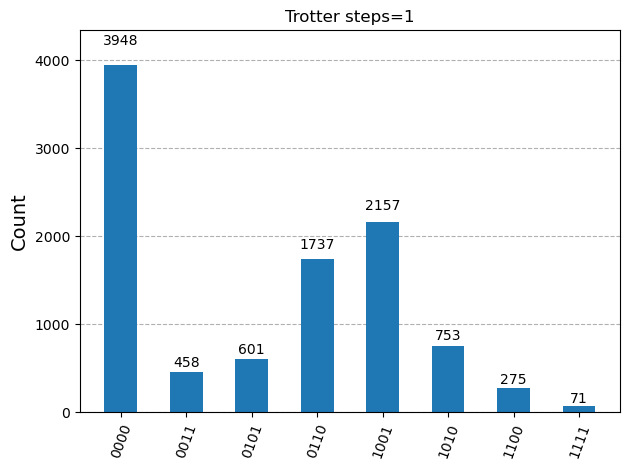

{'1010': 25, '0110': 60, '1001': 186, '1100': 2166, '0000': 676, '0101': 4084, '1111': 209, '0011': 2594}


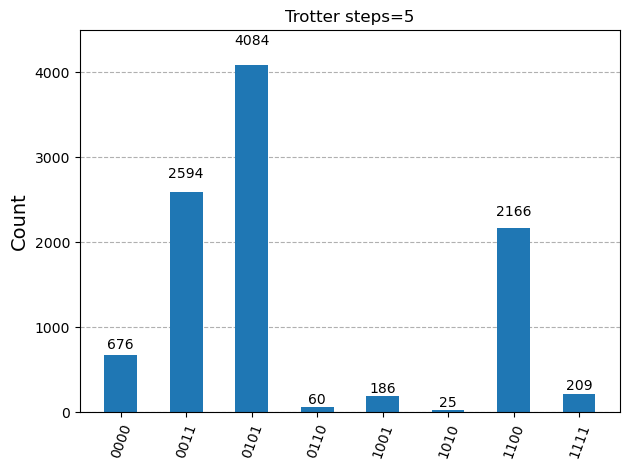

{'1010': 1, '0110': 15, '1001': 48, '1100': 2440, '1111': 51, '0011': 2485, '0000': 174, '0101': 4786}


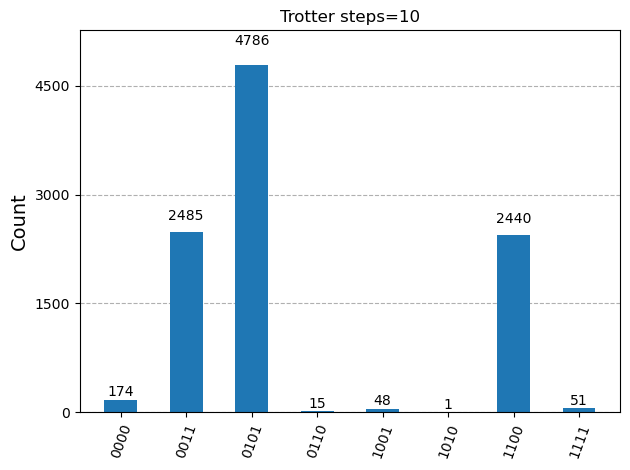

{'0110': 6, '0000': 83, '0011': 2555, '1111': 19, '1001': 28, '1100': 2532, '0101': 4777}


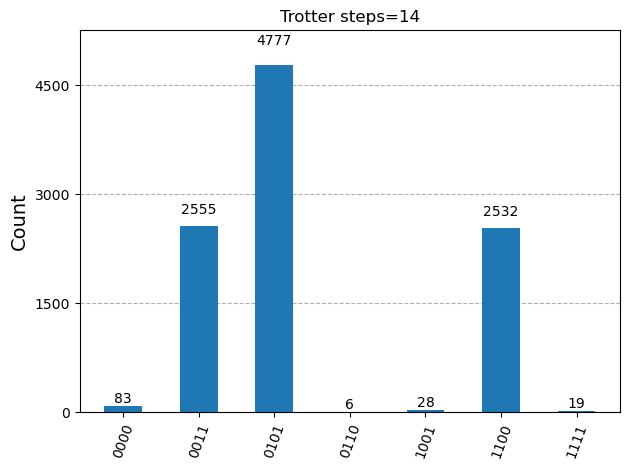

{'0110': 7, '1001': 11, '0011': 2521, '1111': 18, '1100': 2416, '0000': 42, '0101': 4985}


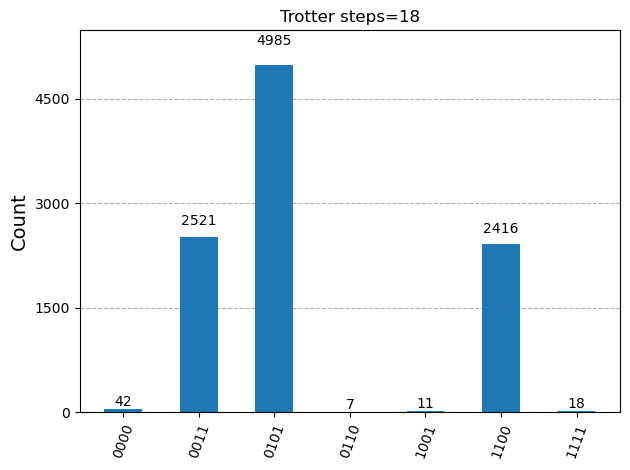

{'1001': 8, '0110': 4, '0011': 2471, '1111': 14, '1100': 2450, '0000': 39, '0101': 5014}


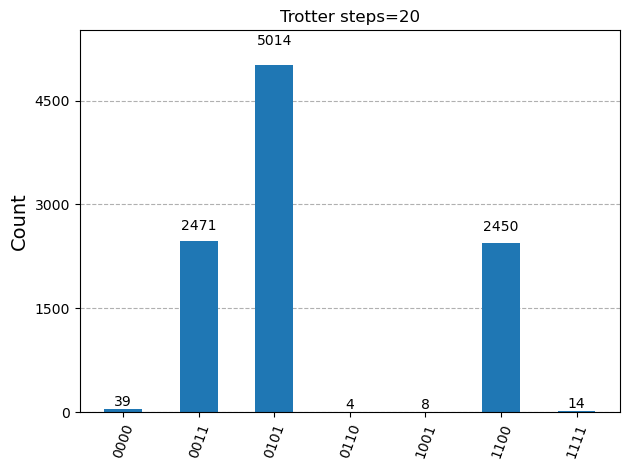

In [2]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Operator, Pauli
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram
from qiskit.synthesis import LieTrotter
from qiskit_aer import AerSimulator
from IPython.display import display, Math
import matplotlib.pyplot as plt
%matplotlib inline

X=Operator(Pauli("X")).data
Y=Operator(Pauli("Y")).data
Z=Operator(Pauli("Z")).data
I=np.eye(2,dtype=complex)

P_0=0.5*(I+Z)
P_1=0.5*(I-Z)

Q_0=0.5*(X+1j*Y)
Q_1=0.5*(X-1j*Y)


I4=np.eye(4,dtype=complex)

###gray define---------------------------------------------------------------------------------
graydag= np.kron(P_0,Q_1) + np.sqrt(2)* np.kron(Q_1,P_1)+ np.sqrt(3)* np.kron(P_1,Q_0)
graynor= np.kron(P_0,Q_0) + np.sqrt(2)* np.kron(Q_0,P_1)+ np.sqrt(3)* np.kron(P_1,Q_1)

graybdag= np.kron(I4,graydag)
grayb=np.kron(I4,graynor)

grayadag= np.kron(graydag,I4)
graya=np.kron(graynor,I4)

H_BS=np.pi/4*(graybdag@graya + grayb@grayadag)

H_BS_P= SparsePauliOp.from_operator(Operator(H_BS))
H_BS_P=H_BS_P.simplify()

###SB define-------------------------------------------------------------------------------------

SBdag= np.kron(P_0,Q_1) + np.sqrt(2)* np.kron(Q_1,Q_0)+ np.sqrt(3)* np.kron(P_1,Q_1)
SBnor= np.kron(P_0,Q_0) + np.sqrt(2)* np.kron(Q_0,Q_1)+ np.sqrt(3)* np.kron(P_1,Q_0)

SBbdag= np.kron(I4,SBdag)
SBb=np.kron(I4,SBnor)

SBadag= np.kron(SBdag,I4)
SBa=np.kron(SBnor,I4)

H_PS=np.pi/4*(SBbdag@SBb)

H_PS_P= SparsePauliOp.from_operator(Operator(H_PS))
H_PS_P=H_PS_P.simplify()

###Circuit define------------------------------------------------------------------------------------

def BScircuit(trotter_steps):
    qc=QuantumCircuit(4,4)
    qc.x(0)
    qc.x(2)
    evolution1= PauliEvolutionGate(H_BS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_BS")
    qc.append(evolution1,[0,1,2,3])
    qc.cx(1,0)
    qc.cx(3,2)
    evolution2= PauliEvolutionGate(H_PS_P,time=1,label="U_PS")
    qc.append(evolution2,[0,1,2,3])
    qc.cx(1,0)
    qc.cx(3,2)
    evolution3= PauliEvolutionGate(H_BS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_BS")
    qc.append(evolution3,[0,1,2,3])
    qc.measure(range(4),range(4))
    return qc

trotter_list=[1,5,10,14,18,20]
backend=AerSimulator()


for n in trotter_list:
    compiled_circuit=transpile(BScircuit(trotter_steps=n), backend)
    job = backend.run(compiled_circuit, shots=10000)
    
    result = job.result()
    counts = result.get_counts()
    print(counts)     
    plot_histogram(counts, title=f"Trotter steps={n}")
    plt.tight_layout()
    plt.show()


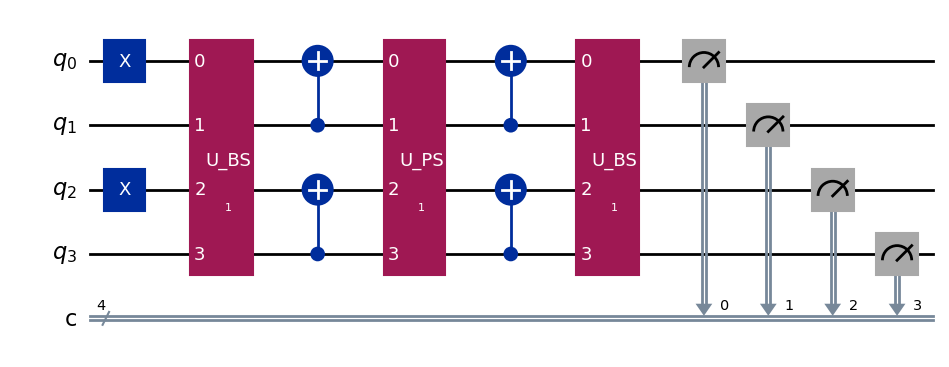

In [3]:
BScircuit(1).draw("mpl")
plt.show()

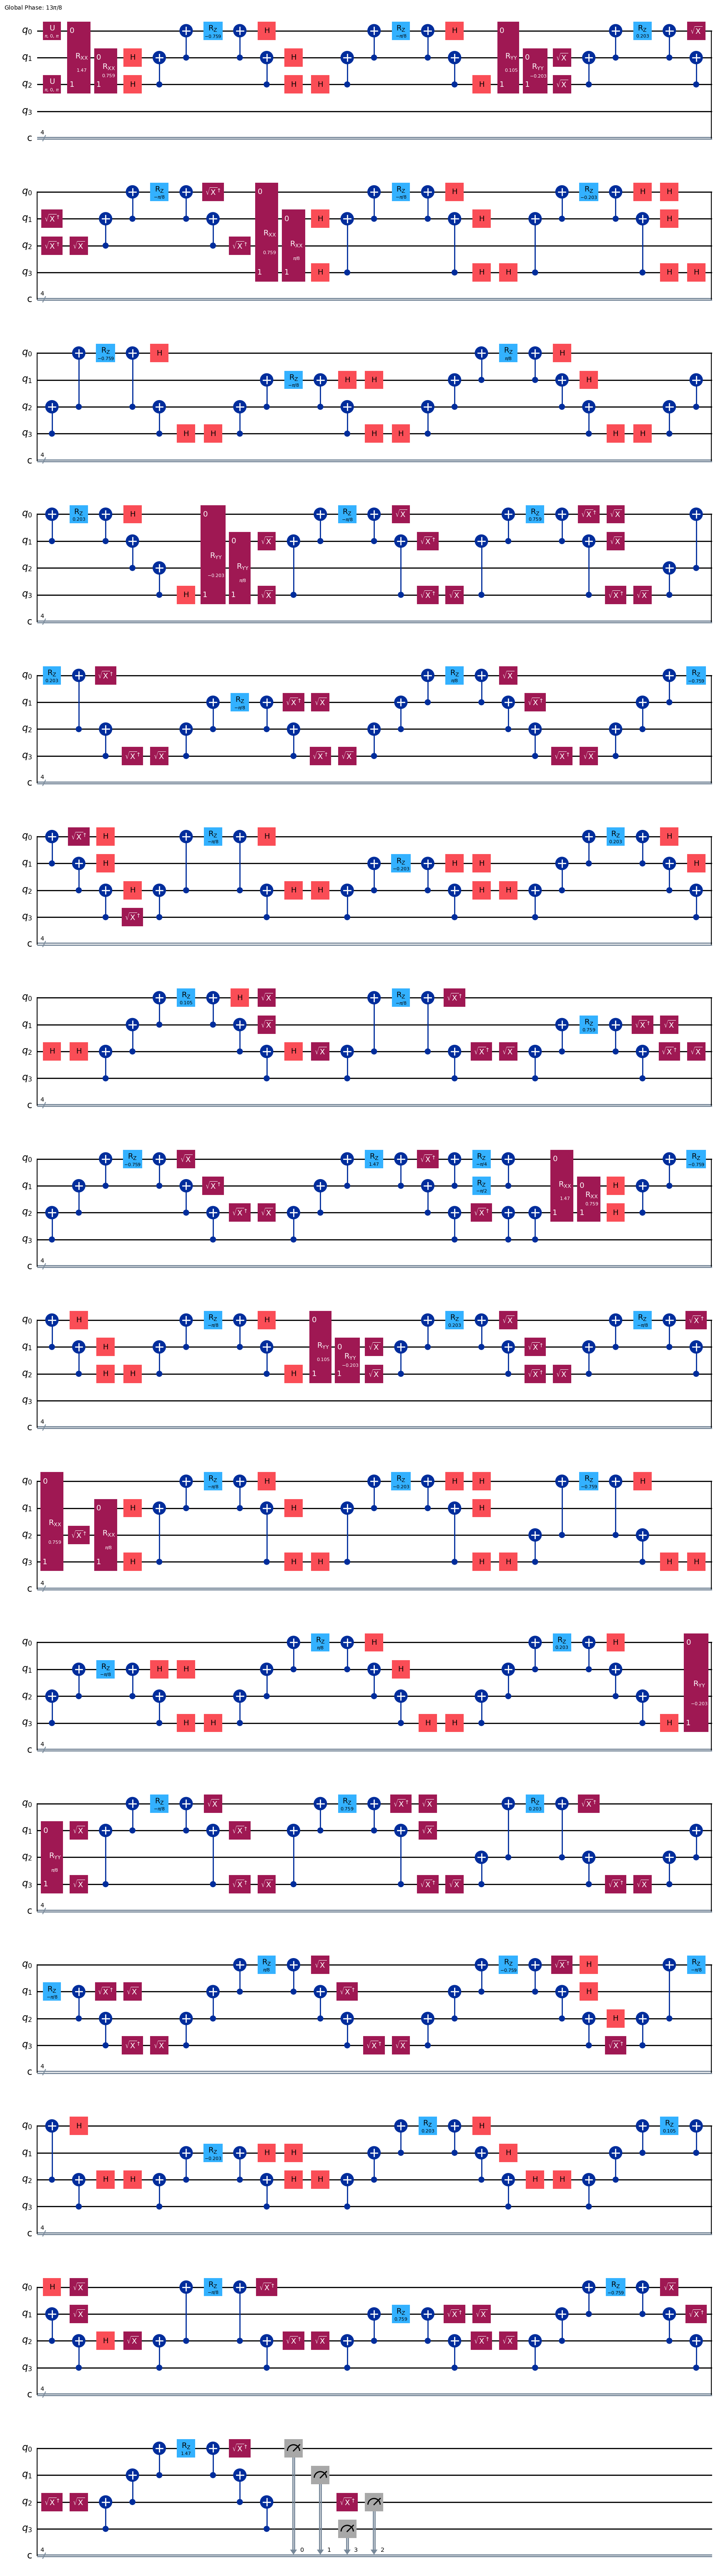

In [4]:
decomposed_circuit=BScircuit(1).decompose()
decomposed_circuit.draw("mpl")
plt.show()

In [5]:
print(decomposed_circuit.depth())

384


In [6]:
print(decomposed_circuit.count_ops())

OrderedDict({'cx': 228, 'h': 96, 'rz': 50, 'sx': 48, 'sxdg': 48, 'rxx': 8, 'ryy': 8, 'measure': 4, 'u': 2})


## Theta sweep

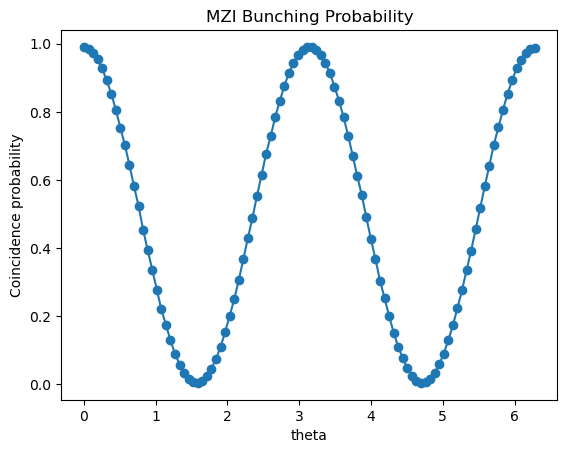

In [3]:
def BScircuit(trotter_steps,phi):
    H_PS=phi*(SBbdag@SBb)

    H_PS_P= SparsePauliOp.from_operator(Operator(H_PS))
    H_PS_P=H_PS_P.simplify()

    
    qc=QuantumCircuit(4,4)
    qc.x(0)
    qc.x(2)
    evolution1= PauliEvolutionGate(H_BS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_BS")
    qc.append(evolution1,[0,1,2,3])
    qc.cx(1,0)
    qc.cx(3,2)
    evolution2= PauliEvolutionGate(H_PS_P,time=1,label="U_PS")
    qc.append(evolution2,[0,1,2,3])
    qc.cx(1,0)
    qc.cx(3,2)
    evolution3= PauliEvolutionGate(H_BS_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_BS")
    qc.append(evolution3,[0,1,2,3])
    qc.measure(range(4),range(4))
    return qc

    



def coincidence_probability(counts, shots):
    total = 0
    for bitstring, c in counts.items():
        bits = bitstring[::-1]   
        m1 = sum(int(b) for b in bits[0:2])
        m2 = sum(int(b) for b in bits[2:4])
        if m1 == 1 and m2 == 1:
            total += c
    return total / shots

backend=AerSimulator()
shots=100000
thetas=np.linspace(0,2*np.pi,100)
coincidences=[]

for phi in thetas:
    qc=BScircuit(20,phi)
    compiled=transpile(qc,backend)
    job=backend.run(compiled, shots=shots)
    result=job.result()
    counts=result.get_counts()
    coincidences.append(coincidence_probability(counts,shots))

plt.plot(thetas, coincidences, 'o-')
plt.xlabel("theta")
plt.ylabel("Coincidence probability")
plt.title("MZI Bunching Probability")
plt.show()